# ER2026 — сравнение систем захвата движений

Исследовательский ноутбук для сравнения **Custom IMU и Noitom**: проверка качества BVH, выравнивание спины, ошибки положений и вращений, корреляции и динамика расхождения.

**Порядок работы:** выполните ячейки сверху вниз. В разделе параметров можно выбрать запись, сустав, участок времени и момент для просмотра позы. Разметка расположена в конце ноутбука и сохраняется только после нажатия кнопки подтверждения.

Для нового окружения из корня репозитория:

```powershell
.venv\Scripts\python.exe -m pip install -e ".[analysis,notebook]"
.venv\Scripts\python.exe -m jupyterlab scripts/ER2026/processing/motion_capture_analysis.ipynb
```

Используйте ядро Python из этого окружения. Исходные записи доступны только для чтения; CSV и рисунки сохраняются в `scripts/ER2026/output/motion_notebook/`.


In [1]:
from pathlib import Path
import sys
import os
import json
import platform
from functools import lru_cache
from datetime import datetime, timezone

def find_project_root(start=None):
    start = Path.cwd() if start is None else Path(start).resolve()
    for candidate in (start, *start.parents):
        if (candidate / "scripts/ER2026/processing/motion.py").is_file():
            return candidate
    raise FileNotFoundError("Откройте ноутбук из репозитория ImuMotionCapture.")

PROJECT_ROOT = find_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

RECORDS_ROOT = PROJECT_ROOT / "scripts/ER2026/records"
OUTPUT_DIR = PROJECT_ROOT / "scripts/ER2026/output/motion_notebook"
LABELS_ROOT = PROJECT_ROOT / "scripts/ER2026/output/annotations"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("MPLCONFIGDIR", str(OUTPUT_DIR / "matplotlib_cache"))

import numpy as np
import pandas as pd
import scipy
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
get_ipython().run_line_magic("matplotlib", "inline")

from scripts.ER2026.processing.pipeline import run
from scripts.ER2026.processing.io import indexed_records
from scripts.ER2026.processing.motion import ARMS, POINTS, load_bvh, require_pair
from scripts.ER2026.processing.comparison import angle_degrees, correlation, compare
from scripts.ER2026.processing.annotations import angular_speed

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.grid": True,
                     "grid.alpha": .22, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", 18)
pd.set_option("display.max_rows", 40)
print("Корень проекта:", PROJECT_ROOT)
print("Python:", platform.python_version(), "| NumPy:", np.__version__,
      "| SciPy:", scipy.__version__, "| pandas:", pd.__version__)


Корень проекта: C:\Users\brody\Desktop\Work\MIPT\MotionCapture\ImuMotionCapture
Python: 3.12.14 | NumPy: 2.5.3 | SciPy: 1.18.1 | pandas: 3.0.6


## 1. Параметры

`RECOMPUTE=True` повторно читает BVH и проверяет хеши; рекомендуемый вариант. При `False` используются сохранённые таблицы этого ноутбука, которые могут устареть после изменения записей.

В `SELECTED_RECORDING` задайте ID каталога из таблицы ниже; `None` выбирает первую пригодную пару SET02. `TIME_RANGE_S` ограничивает подробные графики и расчёт метрик выбранного участка. Общие сводки остаются по полным записям.


In [2]:
RECOMPUTE = True
SELECTED_RECORDING = None
FOCUS_SEGMENT = "LeftForeArm"      # LeftArm / LeftForeArm / RightArm / RightForeArm
FOCUS_POINT = "LeftForeArm.end"    # LeftForeArm = локоть, LeftForeArm.end = запястье
TIME_RANGE_S = (0., 300.)
POSE_TIME_S = 20.
USE_REVIEWED_LABELS = False       # включает сравнение пар по подтверждённым интервалам

def show_save(fig, name):
    fig.savefig(OUTPUT_DIR / (name + ".png"), dpi=150, bbox_inches="tight")
    fig.savefig(OUTPUT_DIR / (name + ".svg"), bbox_inches="tight")
    display(fig)
    plt.close(fig)

def read_table(name):
    path = OUTPUT_DIR / name
    try:
        return pd.read_csv(path, encoding="utf-8-sig")
    except pd.errors.EmptyDataError:
        return pd.DataFrame()

if RECOMPUTE:
    audit = run(RECORDS_ROOT, OUTPUT_DIR, LABELS_ROOT if USE_REVIEWED_LABELS else None)
else:
    audit = json.loads((OUTPUT_DIR / "audit.json").read_text(encoding="utf-8"))
    if audit.get("schema_version", 0) < 2:
        raise ValueError("Устаревший аудит: задайте RECOMPUTE=True.")

inventory = read_table("inventory.csv")
metrics = read_table("comparison.csv")
temporal = read_table("comparison_10s.csv")
interval_metrics = read_table("comparison_intervals.csv")
records = list(indexed_records(RECORDS_ROOT))
record_by_id = {r["recording_id"]: r for r in records}

def record_label(rid):
    row = record_by_id[rid]
    return f'{row["subject_id"]} · {row["word_set_id"]} · {row["timestamp"][:10]}'

pair_ids = [rid for rid, value in audit["lag_diagnostics"].items() if "error" not in value]
if not pair_ids:
    raise ValueError("Нет сопоставимых пар. Сначала изучите inventory и audit.")
if SELECTED_RECORDING is None:
    SELECTED_RECORDING = next((rid for rid in pair_ids
                               if record_by_id[rid]["word_set_id"] == "SET02"), pair_ids[0])
if SELECTED_RECORDING not in pair_ids:
    raise ValueError("Для подробного анализа выберите ID из pair_ids.")
if FOCUS_SEGMENT not in ARMS or FOCUS_POINT not in POINTS:
    raise ValueError("Неизвестный сегмент или точка.")
print("Доступные пары:", *pair_ids, sep="\n")
print("\nВыбрано:", record_label(SELECTED_RECORDING))

print(f'Записей: {audit["indexed_recordings"]}; пар в индексе: {audit["indexed_pairs"]}; '
      f'сопоставимых пар: {audit["successful_comparisons"]}')
display(inventory.reindex(columns=["recording_id", "source", "valid", "frames", "fps",
                                   "duration_s", "max_rotation_step_deg", "warnings", "error"]))


Доступные пары:
20261012_180237_255468_P001_SET01_92aa17
20261015_134311_929859_Alex_mio_SET01_b2c873
20261015_135408_558790_Alex_mio_SET02_a567e2
20261019_162022_434524_P003_SET01_25f342

Выбрано: Alex_mio · SET02 · 2026-10-15
Записей: 7; пар в индексе: 4; сопоставимых пар: 4


,recording_id,source,valid,frames,fps,duration_s,max_rotation_step_deg,warnings,error
0,20261012_180237_255468_P001_SET01_92aa17,custom,True,15001,50.000000,300.0,13.951430,[],NaN
1,20261012_180237_255468_P001_SET01_92aa17,noitom,True,15001,50.000000,300.0,12.399521,[],NaN
2,20261015_134311_929859_Alex_mio_SET01_b2c873,custom,True,15001,50.000000,300.0,12.419993,[],NaN
3,20261015_134311_929859_Alex_mio_SET01_b2c873,noitom,True,15001,50.000000,300.0,13.215728,[],NaN
4,20261015_135408_558790_Alex_mio_SET02_a567e2,custom,True,15001,50.000000,300.0,13.054351,[],NaN
5,20261015_135408_558790_Alex_mio_SET02_a567e2,noitom,True,15001,50.000000,300.0,14.605308,[],NaN
6,20261019_162022_434524_P003_SET01_25f342,custom,True,12000,39.996667,300.0,14.902806,[],NaN
7,20261019_162022_434524_P003_SET01_25f342,noitom,True,12000,39.996667,300.0,15.446696,[],NaN
8,20261021_125211_697542_P003_mio_SET01_596859,noitom,True,15001,50.000000,300.0,14.682410,[],NaN
9,20261021_130127_935575_P001_mio_SET01_012733,noitom,True,15001,50.000000,300.0,13.861946,[],NaN


## 2. Контроль качества и выбор сопоставимых пар

Для сравнения требуются общий скелет, одинаковая геометрия, число кадров и Frame Time. Старый формат PTEST сохраняется в таблице исключений; автоматической конвертации нет. ZIP-копии и старый архив протокола не добавляются как новые наблюдения.

Частота BVH относится к экспортированной сетке. Она не равна частоте независимых аппаратных измерений. Интерполяция может скрывать пропуски исходного потока; дополнительно смотрите журнал приёма.


In [3]:
invalid = inventory.loc[~inventory["valid"].astype(bool)].reindex(
    columns=["recording_id", "source", "error"])
display(Markdown("**Исключённые источники:**"))
display(invalid)
display(Markdown("**Каталоги без BVH:**"))
display(audit["empty_recording_dirs"])
if audit["unindexed_bvh"]:
    display(Markdown("**Неиндексированные BVH:**"))
    display(audit["unindexed_bvh"])

acquisition_rows = []
for rid, entries in audit["acquisition"].items():
    if rid not in record_by_id:
        continue
    for entry in entries:
        export = entry.get("export") or {}
        if entry["status"] == "complete":
            acquisition_rows.append({"recording_id": rid, "frames": export.get("frames"),
                "fps": export.get("fps"), "source_rates_hz": export.get("source_rates_hz"),
                "max_source_gaps_ns": export.get("max_source_gaps_ns")})
display(pd.DataFrame(acquisition_rows))
display(Markdown("**Старый архив протокола, отдельно от BVH:**"))
display(audit["legacy_archive"])

**Исключённые источники:**

,recording_id,source,error


**Каталоги без BVH:**

[]

**Неиндексированные BVH:**

['20261012_153301_504521_PTEST_SET01_e9934a/custom.bvh',
 '20261012_153301_504521_PTEST_SET01_e9934a/noitom.bvh']

,recording_id,frames,fps,source_rates_hz,max_source_gaps_ns
0,20261012_180237_255468_P001_SET01_92aa17,15001,50.000000,"[50.00136429627447, 100.01040299518877]","[67933500, 77898500]"
1,20261015_134311_929859_Alex_mio_SET01_b2c873,15001,50.000000,"[50.00678786398834, 100.02386740332435]","[65113700, 89284900]"
2,20261015_135408_558790_Alex_mio_SET02_a567e2,15001,50.000000,"[50.00593089606811, 100.01120932860668]","[60005800, 48304600]"
3,20261019_162022_434524_P003_SET01_25f342,12000,39.996667,"[39.998758168710644, 49.99970603506165]","[150017900, 69260400]"
4,20261021_125211_697542_P003_mio_SET01_596859,15001,50.000000,[100.01634931479029],[104280500]
5,20261021_130127_935575_P001_mio_SET01_012733,15001,50.000000,[100.01729776598806],[139367100]
6,20261021_130813_079975_P001_mio_SET02_41c5e7,15001,50.000000,[100.03612033606814],[61314700]


**Старый архив протокола, отдельно от BVH:**

{'index_present': True,
 'indexed_presenter_sessions': 5,
 'referenced_motion_files': 8,
 'existing_motion_files': 0,
 'note': 'Historical index presence flags may be stale; not merged into BVH dataset'}

## 3. Что означает выравнивание спины

В каждом кадре для **каждого костюма отдельно**:
$$
R_{body,j}=R_{spine}^{T}R_j,\qquad
p_{body,j}=R_{spine}^{T}(p_j-p_{spine}).
$$

Выравнивание убирает общее положение и поворот туловища. Поэтому ошибка самой спины в `spine` тождественно нулевая и не входит в сводку рук. Её исходная ошибка доступна в `world`.

- **Ориентация сегмента:** геодезический угол между матрицами вращения, 0…180°. Углы Эйлера напрямую не вычитаются.
- **Направление кости:** угол между единичными векторами; осевое вращение сегмента исключено.
- **Положение:** RMS евклидова расстояния локтя/запястья, мм.
- **Локальное вращение:** относительно родителя, для предплечья — относительно плеча.
- **Сгибание локтя:** угол между плечом и предплечьем; прямая рука соответствует 0°.

Основные метрики используют все кадры на исходной общей сетке, включая переходы. Noitom служит системой сравнения, а не доказанным абсолютным эталоном.


frame                           world                                    \
joint                         LeftArm LeftForeArm RightArm RightForeArm   
P001 · SET01 · 2026-10-12       48.47       27.63    45.55        33.09   
Alex_mio · SET01 · 2026-10-15   37.96       37.52    55.48        28.33   
Alex_mio · SET02 · 2026-10-15   53.16       24.14    36.07        30.20   
P003 · SET01 · 2026-10-19       87.74       66.93    93.25        69.34   

frame                           spine                                    
joint                         LeftArm LeftForeArm RightArm RightForeArm  
P001 · SET01 · 2026-10-12       83.71       73.05    83.28        56.97  
Alex_mio · SET01 · 2026-10-15  129.36      129.23   132.37       128.62  
Alex_mio · SET02 · 2026-10-15   43.85       25.96    37.63        33.02  
P003 · SET01 · 2026-10-19      115.14      125.08   115.44       134.80

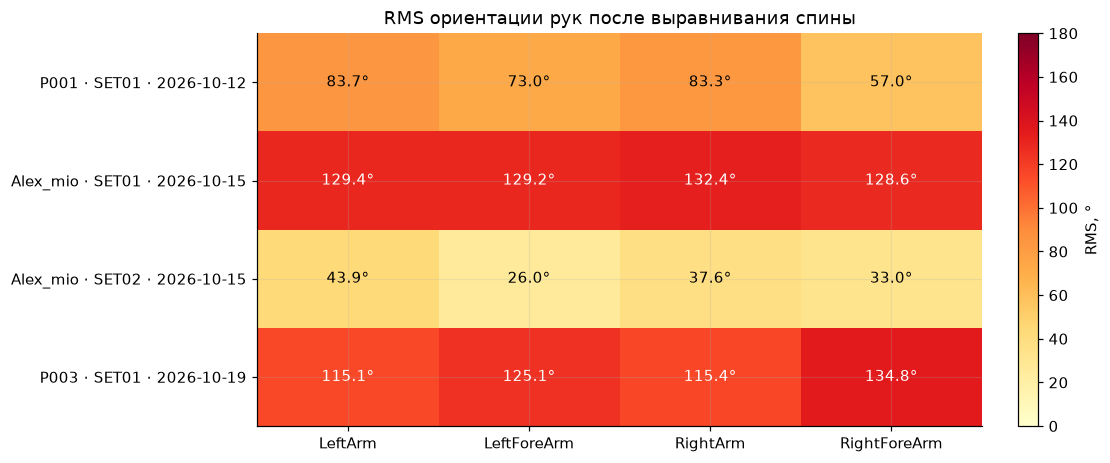

In [4]:
rotation = metrics.query("kind == 'rotation_deg' and frame in ['world', 'spine']")
rotation = rotation[rotation["joint"].isin(ARMS)]
rotation_table = rotation.pivot(index="recording_id", columns=["frame", "joint"], values="rms")
rotation_table.index = [record_label(rid) for rid in rotation_table.index]
display(rotation_table.round(2))

aligned = rotation.query("frame == 'spine'").pivot(index="recording_id", columns="joint", values="rms")
aligned = aligned.reindex(columns=ARMS)
rotation_ids = aligned.index.tolist()
fig, ax = plt.subplots(figsize=(10, max(3., .65 * len(rotation_ids) + 1.5)), layout="constrained")
im = ax.imshow(aligned.to_numpy(float), vmin=0, vmax=180, cmap="YlOrRd", aspect="auto")
ax.set_xticks(range(len(ARMS)), ARMS)
ax.set_yticks(range(len(rotation_ids)), [record_label(rid) for rid in rotation_ids])
for i in range(len(rotation_ids)):
    for j in range(len(ARMS)):
        value = aligned.iloc[i, j]
        ax.text(j, i, f"{value:.1f}°", ha="center", va="center",
                color="white" if value > 100 else "black")
ax.set_title("RMS ориентации рук после выравнивания спины")
fig.colorbar(im, ax=ax, label="RMS, °")
show_save(fig, "01_rotation_rms")


## 4. Положения локтей и запястий

Точки получены прямой кинематикой на **общей геометрии**: это не независимые измерения положения маркеров. `LeftForeArm` / `RightForeArm` — локти, суффикс `.end` — запястья. RMS положения — $\sqrt{\operatorname{mean}(\|p_C-p_N\|^2)}$, а не среднее RMS по трём координатам.


joint,LeftForeArm,LeftForeArm.end,RightForeArm,RightForeArm.end
P001 · SET01 · 2026-10-12,559.7,1003.5,443.3,737.6
Alex_mio · SET01 · 2026-10-15,731.9,1367.9,745.2,1405.6
Alex_mio · SET02 · 2026-10-15,294.7,336.3,195.6,323.5
P003 · SET01 · 2026-10-19,402.3,774.9,478.8,891.4


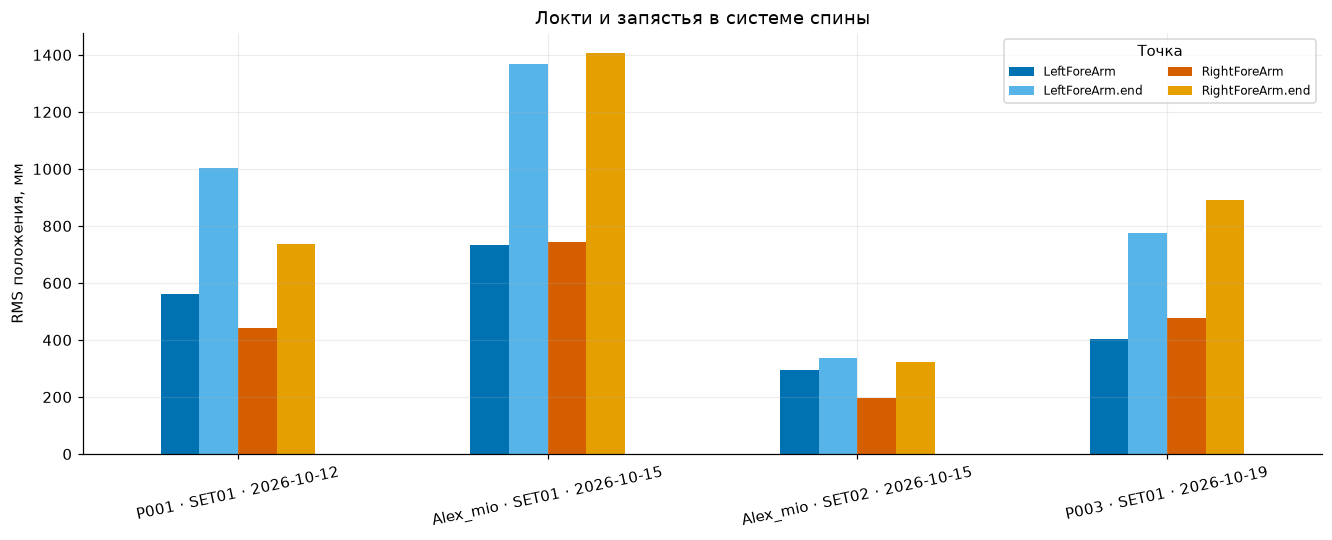

In [5]:
position = metrics.query("kind == 'position_mm' and frame == 'spine'")
position_table = position.pivot(index="recording_id", columns="joint", values="rms")
position_table = position_table.reindex(columns=POINTS)
position_table.index = [record_label(rid) for rid in position_table.index]
display(position_table.round(1))
fig, ax = plt.subplots(figsize=(12, 4.8), layout="constrained")
position_table.plot.bar(ax=ax, rot=12, color=["#0072B2", "#56B4E9", "#D55E00", "#E69F00"])
ax.set(ylabel="RMS положения, мм", xlabel="", title="Локти и запястья в системе спины")
ax.legend(title="Точка", ncol=2, fontsize=8)
show_save(fig, "02_position_rms")


## 5. Корреляции направлений рук

Pearson показан по **всем трём координатам**, без выбора лучшей оси. Постоянный сигнал имеет неопределённую корреляцию (`NaN`), а не ноль или единицу. Высокая корреляция сама по себе не означает малую абсолютную ошибку.


pearson_x                       \
                                               LeftArm LeftForeArm RightArm   
recording_id                                                                  
20261012_180237_255468_P001_SET01_92aa17        -0.464      -0.138    0.808   
20261015_134311_929859_Alex_mio_SET01_b2c873    -0.514      -0.457   -0.165   
20261015_135408_558790_Alex_mio_SET02_a567e2     0.628       0.977    0.822   
20261019_162022_434524_P003_SET01_25f342        -0.248      -0.223   -0.142   

                                                          pearson_y  \
                                             RightForeArm   LeftArm   
recording_id                                                          
20261012_180237_255468_P001_SET01_92aa17            0.912     0.675   
20261015_134311_929859_Alex_mio_SET01_b2c873       -0.259     0.144   
20261015_135408_558790_Alex_mio_SET02_a567e2        0.783     0.894   
20261019_162022_434524_P003_SET01_25f342           -0.496     0.856   

                                                                   \
                                             LeftForeArm RightArm   
recording_id                                                        
20261012_180237_255468_P001_SET01_92aa17           0.708   -0.139   
20261015_134311_929859_Alex_mio_SET01_b2c873      -0.056   -0.236   
20261015_135408_558790_Alex_mio_SET02_a567e2       0.994    0.979   
20261019_162022_434524_P003_SET01_25f342           0.669    0.840   

                                                          pearson_z  \
                                             RightForeArm   LeftArm   
recording_id                                                          
20261012_180237_255468_P001_SET01_92aa17            0.065    -0.072   
20261015_134311_929859_Alex_mio_SET01_b2c873       -0.369     0.611   
20261015_135408_558790_Alex_mio_SET02_a567e2        0.968     0.808   
20261019_162022_434524_P003_SET01_25f342            0.900    -0.220   

                                                                                
                                             LeftForeArm RightArm RightForeArm  
recording_id                                                                    
20261012_180237_255468_P001_SET01_92aa17           0.868   -0.623        0.689  
20261015_134311_929859_Alex_mio_SET01_b2c873       0.647    0.416        0.312  
20261015_135408_558790_Alex_mio_SET02_a567e2       0.738    0.799        0.728  
20261019_162022_434524_P003_SET01_25f342          -0.187    0.039        0.283

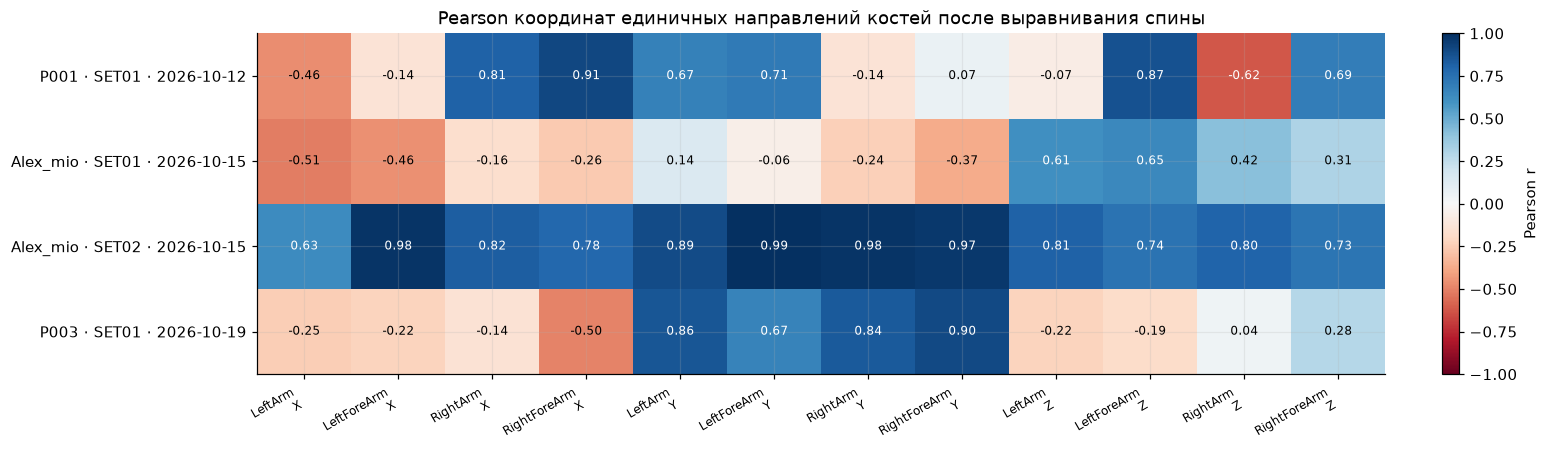

In [6]:
direction_rows = metrics.query("kind == 'direction_deg' and frame == 'spine'")
corr = direction_rows.pivot(index="recording_id", columns="joint",
                            values=["pearson_x", "pearson_y", "pearson_z"])
corr = corr.reindex(columns=pd.MultiIndex.from_product(
    [["pearson_x", "pearson_y", "pearson_z"], ARMS]))
correlation_ids = corr.index.tolist()
display(corr.round(3))
fig, ax = plt.subplots(figsize=(14, max(3., .65 * len(correlation_ids) + 1.5)), layout="constrained")
cmap = plt.get_cmap("RdBu").copy()
cmap.set_bad("#dddddd")
im = ax.imshow(np.ma.masked_invalid(corr.to_numpy(float)), vmin=-1, vmax=1, cmap=cmap, aspect="auto")
ax.set_xticks(range(len(corr.columns)), [f"{joint}\n{axis[-1].upper()}" for axis, joint in corr.columns],
              rotation=30, ha="right", fontsize=8)
ax.set_yticks(range(len(correlation_ids)), [record_label(rid) for rid in correlation_ids])
for i in range(len(correlation_ids)):
    for j in range(len(corr.columns)):
        value = corr.iloc[i, j]
        if np.isfinite(value):
            ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=8,
                    color="white" if abs(value) > .6 else "black")
ax.set_title("Pearson координат единичных направлений костей после выравнивания спины")
fig.colorbar(im, ax=ax, label="Pearson r")
show_save(fig, "03_direction_correlations")


## 6. Сгибание локтей и локальные вращения

Сгибание локтя и полная ориентация предплечья оценивают разные движения. Величина `bias` имеет знак Custom − Noitom. Малая амплитуда сгибания может делать Pearson нестабильным даже при небольшом RMS.


In [7]:
elbows = metrics.query("kind == 'elbow_flexion_deg'").copy()
elbows["recording"] = elbows["recording_id"].map(record_label)
display(elbows[["recording", "joint", "rms", "median", "p95", "bias", "pearson"]].round(3))
local = metrics.query("frame == 'parent' and kind == 'rotation_deg'").pivot(
    index="recording_id", columns="joint", values="rms")
local.index = [record_label(rid) for rid in local.index]
display(Markdown("**RMS локального вращения относительно родительского сегмента, °:**"))
display(local.round(2))


,recording,joint,rms,median,p95,bias,pearson
22,P001 · SET01 · 2026-10-12,LeftElbow,9.100,8.580,14.228,3.225,0.710
23,P001 · SET01 · 2026-10-12,RightElbow,23.187,14.893,47.286,17.833,0.338
50,Alex_mio · SET01 · 2026-10-15,LeftElbow,20.512,14.448,37.966,15.288,0.191
51,Alex_mio · SET01 · 2026-10-15,RightElbow,21.485,11.584,45.000,15.430,0.272
78,Alex_mio · SET02 · 2026-10-15,LeftElbow,32.276,16.397,68.007,21.821,-0.097
79,Alex_mio · SET02 · 2026-10-15,RightElbow,7.499,4.789,14.844,-1.471,0.599
106,P003 · SET01 · 2026-10-19,LeftElbow,27.927,23.235,51.029,23.789,0.068
107,P003 · SET01 · 2026-10-19,RightElbow,41.696,13.658,108.797,25.886,0.508


**RMS локального вращения относительно родительского сегмента, °:**

joint,LeftArm,LeftForeArm,RightArm,RightForeArm
P001 · SET01 · 2026-10-12,83.71,29.80,83.28,38.60
Alex_mio · SET01 · 2026-10-15,129.36,32.51,132.37,49.81
Alex_mio · SET02 · 2026-10-15,43.85,42.41,37.63,21.88
P003 · SET01 · 2026-10-19,115.14,43.82,115.44,75.61


## 7. Как ошибка меняется во времени

Непересекающиеся окна примерно по 10 секунд. Слева — полная ориентация сегментов, справа — направление костей. Временная структура помогает отделить постоянное расхождение от накопления ошибки, но не устанавливает причину дрейфа.


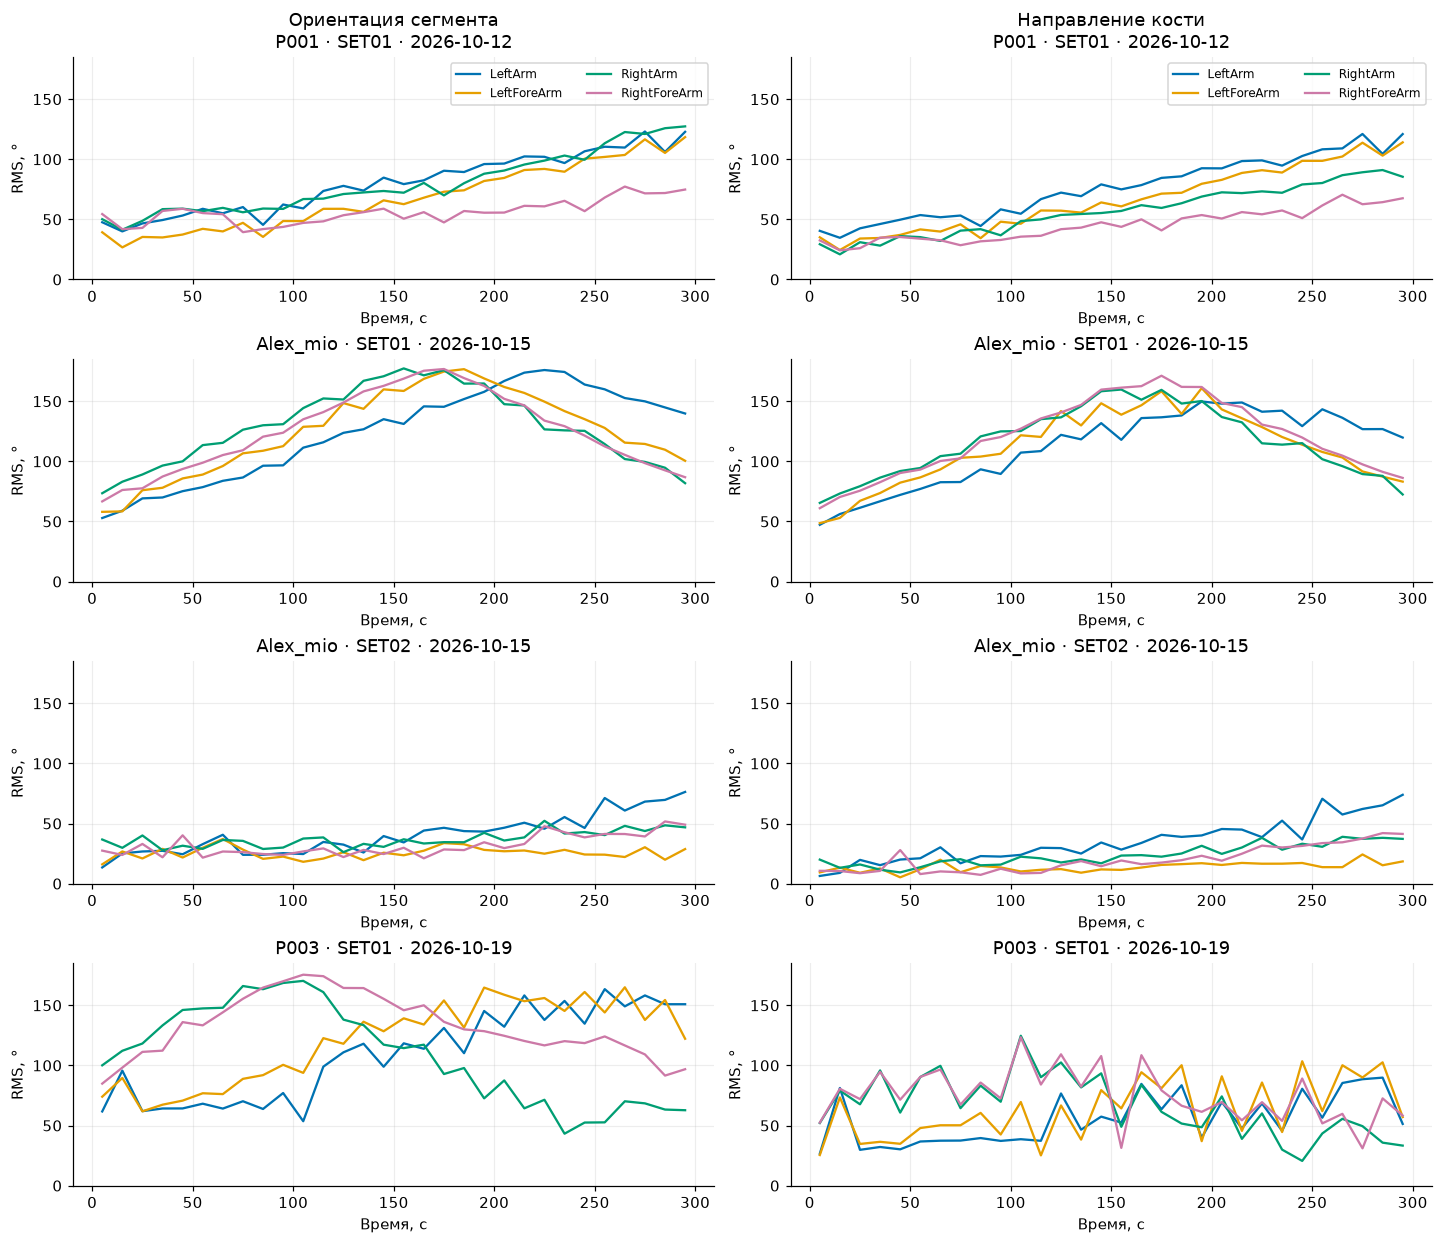

In [8]:
temporal_ids = sorted(temporal["recording_id"].unique())
fig, axes = plt.subplots(len(temporal_ids), 2, figsize=(13, 2.8 * len(temporal_ids)), squeeze=False,
                         layout="constrained")
colors = ["#0072B2", "#E69F00", "#009E73", "#CC79A7"]
for row, rid in enumerate(temporal_ids):
    for col, kind in enumerate(["rotation_deg", "direction_deg"]):
        ax = axes[row, col]
        subset = temporal[(temporal["recording_id"] == rid) & (temporal["kind"] == kind)]
        for joint, color in zip(ARMS, colors):
            data = subset[subset["joint"] == joint].sort_values("start_s")
            ax.plot((data["start_s"] + data["end_s"]) / 2, data["rms"], label=joint, color=color)
        ax.set(title=record_label(rid), xlabel="Время, с", ylabel="RMS, °", ylim=(0, 185))
        if row == 0:
            ax.legend(ncol=2, fontsize=8)
axes[0, 0].set_title("Ориентация сегмента\n" + axes[0, 0].get_title())
axes[0, 1].set_title("Направление кости\n" + axes[0, 1].get_title())
show_save(fig, "04_error_over_time")


## 8. Подробный анализ выбранной пары

Далее используются `SELECTED_RECORDING`, `FOCUS_SEGMENT`, `FOCUS_POINT`, `TIME_RANGE_S` из раздела параметров. Для повторной загрузки изменённых BVH вызовите `get_pair.cache_clear()`.

Метрики участка считаются по его фактическим кадрам. Автоматического выбора удобного временного сдвига или поворота для улучшения результата нет.


Alex_mio · SET02 · 2026-10-15 · 15000 кадров · 0.000…299.980 с


,measure,rms,median,p95
0,LeftForeArm · rotation_deg,25.960,21.695,41.888
1,LeftForeArm.end · position_mm,336.331,270.002,584.710
2,Spine · world rotation_deg,16.490,13.623,27.870


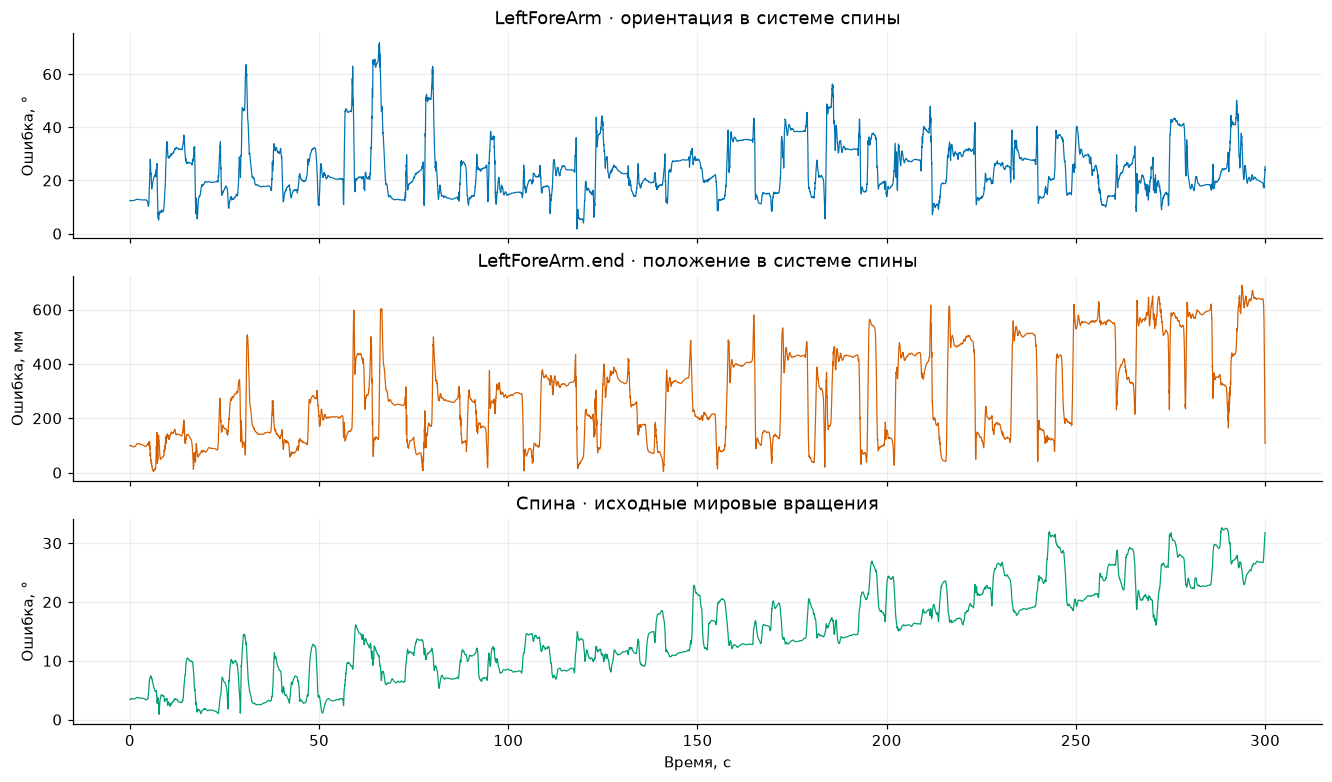

In [9]:
@lru_cache(maxsize=2)
def get_pair(recording_id):
    row = record_by_id[recording_id]
    a, b = (load_bvh(row["paths"][source]) for source in ("custom", "noitom"))
    require_pair(a, b)
    return a, b

custom, noitom = get_pair(SELECTED_RECORDING)
times = np.arange(custom.count) * custom.dt
lo, hi = map(float, TIME_RANGE_S)
if not np.isfinite([lo, hi]).all() or not 0 <= lo < hi:
    raise ValueError("TIME_RANGE_S должен задавать конечный интервал 0 <= начало < конец.")
mask = (times >= lo) & (times < min(hi, custom.duration + custom.dt))
if mask.sum() < 3:
    raise ValueError("В выбранном диапазоне должно быть минимум три кадра.")

body_c, body_n = custom.body_rotations(), noitom.body_rotations()
joint_index = custom.index(FOCUS_SEGMENT)
point_index = POINTS.index(FOCUS_POINT)
rot_error = angle_degrees(body_c[:, joint_index], body_n[:, joint_index])
points_c, points_n = custom.points(), noitom.points()
point_error = np.linalg.norm(points_c[:, point_index] - points_n[:, point_index], axis=1) * 1000
spine_error = angle_degrees(custom.rotations[:, custom.index("Spine")],
                            noitom.rotations[:, noitom.index("Spine")])

detail_summary = pd.DataFrame([
    {"measure": FOCUS_SEGMENT + " · rotation_deg", "rms": np.sqrt(np.mean(rot_error[mask]**2)),
     "median": np.median(rot_error[mask]), "p95": np.percentile(rot_error[mask], 95)},
    {"measure": FOCUS_POINT + " · position_mm", "rms": np.sqrt(np.mean(point_error[mask]**2)),
     "median": np.median(point_error[mask]), "p95": np.percentile(point_error[mask], 95)},
    {"measure": "Spine · world rotation_deg", "rms": np.sqrt(np.mean(spine_error[mask]**2)),
     "median": np.median(spine_error[mask]), "p95": np.percentile(spine_error[mask], 95)}
])
print(record_label(SELECTED_RECORDING), f"· {mask.sum()} кадров · {times[mask][0]:.3f}…{times[mask][-1]:.3f} с")
display(detail_summary.round(3))

fig, axes = plt.subplots(3, 1, figsize=(12, 7), sharex=True, layout="constrained")
axes[0].plot(times[mask], rot_error[mask], color="#0072B2", lw=.8)
axes[0].set(ylabel="Ошибка, °", title=FOCUS_SEGMENT + " · ориентация в системе спины")
axes[1].plot(times[mask], point_error[mask], color="#D55E00", lw=.8)
axes[1].set(ylabel="Ошибка, мм", title=FOCUS_POINT + " · положение в системе спины")
axes[2].plot(times[mask], spine_error[mask], color="#009E73", lw=.8)
axes[2].set(ylabel="Ошибка, °", xlabel="Время, с", title="Спина · исходные мировые вращения")
show_save(fig, "05_selected_errors")


### Координаты точки: временные ряды и диаграммы соответствия

Пунктир на scatter — линия равенства Custom = Noitom. Здесь видны смещение и изменение масштаба, которые корреляция может скрывать.


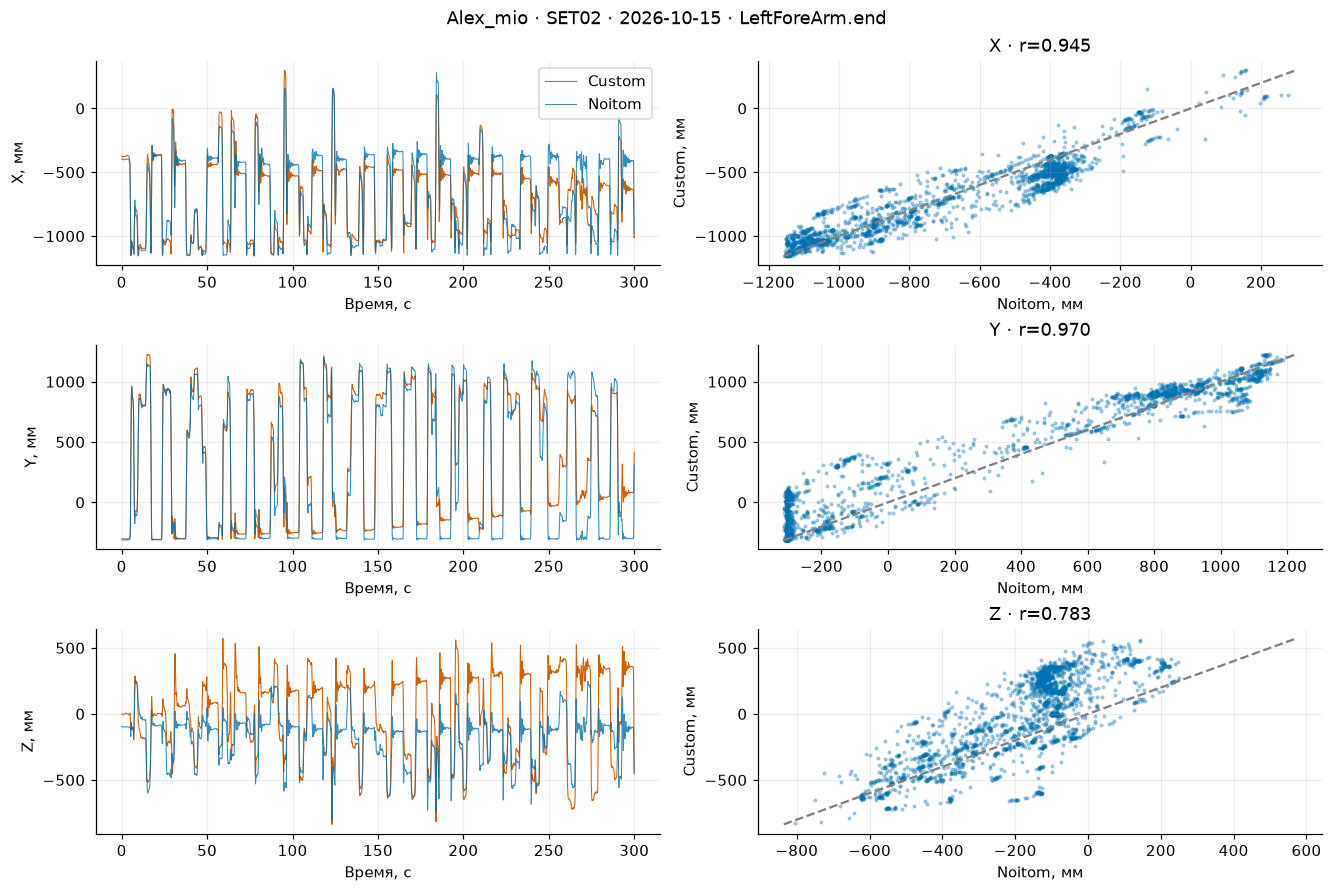

,axis,pearson,rmse_mm,bias_mm
0,X,0.945,114.238,-34.349
1,Y,0.970,165.932,88.513
2,Z,0.783,269.323,181.188


In [10]:
fig, axes = plt.subplots(3, 2, figsize=(12, 8), layout="constrained")
coordinate_stats = []
for j, axis_name in enumerate("XYZ"):
    c, n = points_c[mask, point_index, j] * 1000, points_n[mask, point_index, j] * 1000
    r = correlation(c, n)
    coordinate_stats.append({"axis": axis_name, "pearson": r,
                             "rmse_mm": np.sqrt(np.mean((c - n)**2)), "bias_mm": np.mean(c - n)})
    axes[j, 0].plot(times[mask], c, label="Custom", lw=.7, color="#D55E00")
    axes[j, 0].plot(times[mask], n, label="Noitom", lw=.7, color="#0072B2", alpha=.8)
    axes[j, 0].set(ylabel=axis_name + ", мм", xlabel="Время, с")
    if j == 0:
        axes[j, 0].legend()
    stride = max(1, len(c) // 2500)
    axes[j, 1].scatter(n[::stride], c[::stride], s=3, alpha=.3, color="#0072B2")
    low, high = min(c.min(), n.min()), max(c.max(), n.max())
    if high - low < 1e-6:
        low, high = low - 1, high + 1
    axes[j, 1].plot([low, high], [low, high], "--", color="gray")
    axes[j, 1].set(xlabel="Noitom, мм", ylabel="Custom, мм",
                   title=axis_name + " · r=" + (f"{r:.3f}" if r is not None else "не определён"))
fig.suptitle(record_label(SELECTED_RECORDING) + " · " + FOCUS_POINT)
show_save(fig, "06_selected_coordinates")
display(pd.DataFrame(coordinate_stats).round(3))


### Наложение поз после выравнивания спины

Выберите `POSE_TIME_S` в секундах от начала BVH. На фронтальной проекции левая рука участника находится справа на изображении. Показаны верхняя часть скелета и запястья; обе системы используют общие длины костей.


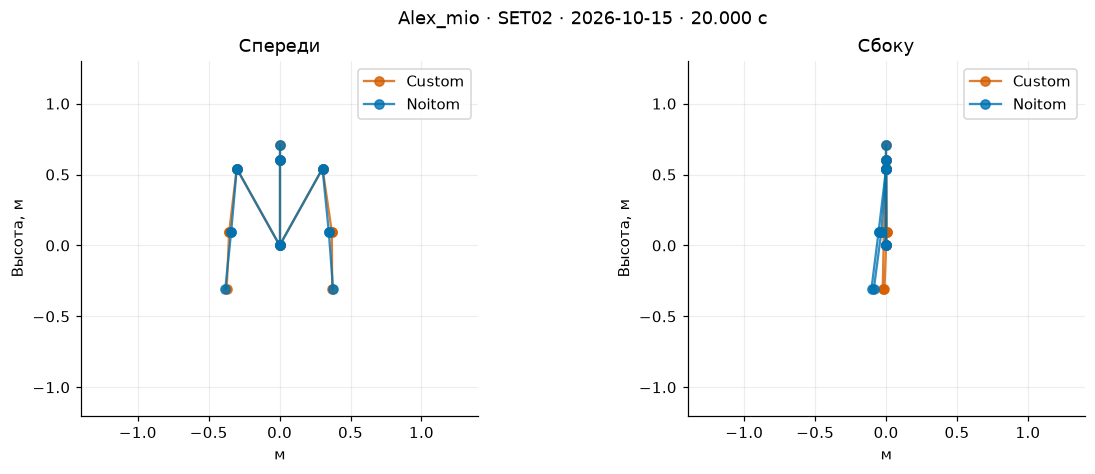

In [11]:
if not np.isfinite(POSE_TIME_S) or not 0 <= POSE_TIME_S <= custom.duration:
    raise ValueError("POSE_TIME_S должен находиться внутри записи.")
pose_frame = min(custom.count - 1, round(POSE_TIME_S / custom.dt))
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), layout="constrained")
for source, motion, color in [("Custom", custom, "#D55E00"), ("Noitom", noitom, "#0072B2")]:
    p, r = motion.body_positions()[pose_frame], motion.body_rotations()[pose_frame]
    for col, ax in enumerate(axes):
        first_line = True
        for i, name in enumerate(motion.names):
            parent = motion.parents[i]
            if parent is not None and name in ("Chest", "Head", *ARMS):
                xyz = p[[parent, i]]
                ax.plot(-xyz[:, 0] if col == 0 else xyz[:, 2], xyz[:, 1], "o-", color=color,
                        alpha=.8, label=source if first_line else None)
                first_line = False
            if name in ("LeftForeArm", "RightForeArm"):
                xyz = np.stack((p[i], p[i] + r[i] @ motion.ends[i]))
                ax.plot(-xyz[:, 0] if col == 0 else xyz[:, 2], xyz[:, 1], "o-", color=color, alpha=.8)
for ax, title in zip(axes, ["Спереди", "Сбоку"]):
    ax.set(title=title, xlim=(-1.4, 1.4), ylim=(-1.2, 1.3), xlabel="м", ylabel="Высота, м")
    ax.set_aspect("equal")
    ax.legend()
fig.suptitle(record_label(SELECTED_RECORDING) + f" · {times[pose_frame]:.3f} с")
show_save(fig, "07_pose_overlay")



## 9. Диагностика временной задержки

Общая шкала времени приёма не устраняет задержки устройств. В аудите ищется максимум корреляции скоростей направлений в пределах ±0,5 с. Положительный lag означает, что Noitom приходит позже Custom.

Это **диагностический подбор на той же записи**, а не независимое измерение аппаратной задержки. Найденный сдвиг не применяется к основным метрикам. Если максимум на краю диапазона или корреляция слаба, интерпретация особенно ограничена.


,recording,best_lag_s,speed_correlation,search_limit_s,applied,at_search_boundary
0,P001 · SET01 · 2026-10-12,0.02,0.9209,0.500,False,False
1,Alex_mio · SET01 · 2026-10-15,0.02,0.9113,0.500,False,False
2,Alex_mio · SET02 · 2026-10-15,0.02,0.9285,0.500,False,False
3,P003 · SET01 · 2026-10-19,0.10,0.8467,0.475,False,False


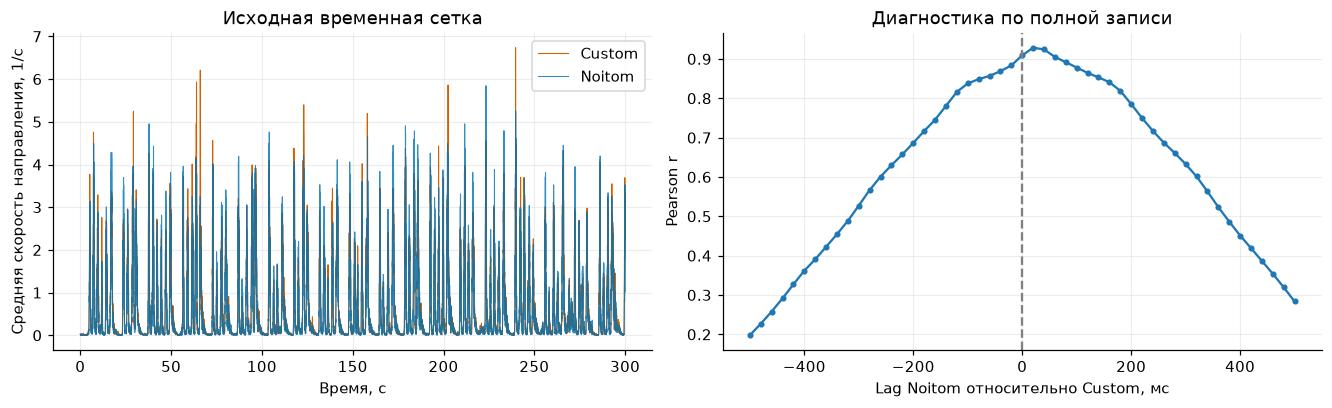

In [12]:
lag_table = pd.DataFrame([dict(recording_id=rid, **audit["lag_diagnostics"][rid]) for rid, value in audit["lag_diagnostics"].items() if "error" not in value])
lag_table.insert(1, "recording", lag_table["recording_id"].map(record_label))
display(lag_table.drop(columns="recording_id").round(4))

dc, dn = custom.directions(), noitom.directions()
speed_c = np.linalg.norm(np.diff(dc, axis=0), axis=-1).mean(axis=1) / custom.dt
speed_n = np.linalg.norm(np.diff(dn, axis=0), axis=-1).mean(axis=1) / noitom.dt
max_lag = min(int(.5 / custom.dt), len(speed_c) // 4)
lag_samples, lag_scores = [], []
for lag in range(-max_lag, max_lag + 1):
    a = speed_c[max(0, -lag):len(speed_c) - max(0, lag)]
    b = speed_n[max(0, lag):len(speed_n) - max(0, -lag)]
    lag_samples.append(lag * custom.dt)
    score = correlation(a, b)
    lag_scores.append(np.nan if score is None else score)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), layout="constrained")
visible = mask[1:]
axes[0].plot(times[1:][visible], speed_c[visible], label="Custom", lw=.7, color="#D55E00")
axes[0].plot(times[1:][visible], speed_n[visible], label="Noitom", lw=.7, color="#0072B2", alpha=.8)
axes[0].set(xlabel="Время, с", ylabel="Средняя скорость направления, 1/с", title="Исходная временная сетка")
axes[0].legend()
axes[1].plot(np.array(lag_samples) * 1000, lag_scores, "o-", ms=3)
axes[1].axvline(0, color="gray", ls="--")
axes[1].set(xlabel="Lag Noitom относительно Custom, мс", ylabel="Pearson r", title="Диагностика по полной записи")
show_save(fig, "08_lag_diagnostic")


## Дальнейшая работа

Для обучения и сравнения классификаторов откройте [semaphore_classification.ipynb](semaphore_classification.ipynb). Ручная разметка выполняется в отдельном приложении: `python -m scripts.ER2026.processing annotate` из корня проекта.
